# code_031 · Learning from actions and overlapping categories

**Book:** section 6.5. These are synthetic mechanism experiments, not observed structural performance, safety assessment, a causal study or an estimator leaderboard. Each experiment states which cases are unseen and which outcomes are available. Fits and preprocessing use training observations only. Development curves support diagnosis; final outcomes are opened only after the stated rule is fixed. Constructed identities and stress cases are not held-out population estimates.

Restart and run all cells. All imports, helpers and data generation are here; no ordinary-run files, network, API key, GPU or private module is required. Use the [quickstart](../README.md), [pinned environment](../requirements-lock.txt), [traceability guide](../CHAPTER_06_GUIDE.md), [execution evidence](../CHAPTER_06_EXECUTION.md) and [permanent registry](../CODE_EXAMPLES.md#code_031). Reference environment: CPython 3.14.3, NumPy 2.4.4, SciPy 1.17.1, pandas 3.0.3, Matplotlib 3.11.0, scikit-learn 1.9.0, CPU. Allow a minute for execution and 30–60 minutes for interpretation. These scoped labs disclose relevant controls rather than cover every constructor parameter.


In [1]:
import platform,time,json
import numpy as np
import scipy,pandas as pd,matplotlib,matplotlib.pyplot as plt,sklearn
from IPython.display import display
START=time.perf_counter();SEED=631;rng=np.random.default_rng(SEED)
VERSIONS={'python':platform.python_version(),'numpy':np.__version__,'scipy':scipy.__version__,'pandas':pd.__version__,'matplotlib':matplotlib.__version__,'scikit-learn':sklearn.__version__}
print(VERSIONS);print('CPU:',platform.system(),platform.machine(),'seed:',SEED)
plt.rcParams.update({'figure.dpi':110,'font.size':11,'axes.spines.top':False,'axes.spines.right':False,'figure.constrained_layout.use':True})
RESULTS={}


{'python': '3.14.3', 'numpy': '2.4.4', 'scipy': '1.17.1', 'pandas': '3.0.3', 'matplotlib': '3.11.0', 'scikit-learn': '1.9.0'}
CPU: Darwin arm64 seed: 631


<a id="bandit"></a>
## Actions reveal selected feedback

A synthetic contextual bandit has two observed states (0,1) and two available actions (0,1). Mean utility table is [[.7,.1],[-.5,.6]], with independent Gaussian reward noise sd .15. Utilities are invented teaching units, not measured inspection costs. Each round's state is an independent fair draw; actions do not change future states, so this is the one-step special case rather than a full sequential-control task.

Train 4000 rounds with epsilon-greedy exploration epsilon=.1. Start action-value estimates at zero. With probability .1 choose a random action; otherwise choose a current maximizer with random tie-breaking. Observe only the chosen action's reward and update its running mean. The known simulator table is withheld from the learner and used only to check the constructed experiment.


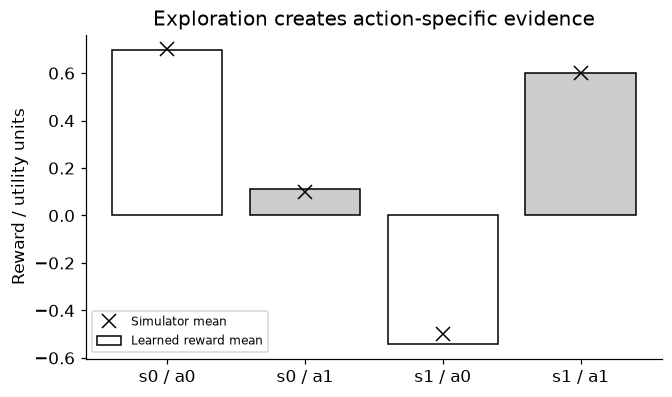

In [2]:
mean_reward=np.array([[.7,.1],[-.5,.6]]);estimates=np.zeros((2,2));counts=np.zeros((2,2),dtype=int);reward_history=[]
for step in range(4000):
 state=int(rng.integers(2))
 action=int(rng.integers(2)) if rng.random()<.1 else int(rng.choice(np.flatnonzero(estimates[state]==estimates[state].max())))
 reward=float(mean_reward[state,action]+rng.normal(0,.15));counts[state,action]+=1
 estimates[state,action]+=(reward-estimates[state,action])/counts[state,action];reward_history.append(reward)
policy=estimates.argmax(1)
assert np.all(counts>0) and counts.sum()==4000 and np.all(np.isin(policy,[0,1]))
assert np.array_equal(policy,mean_reward.argmax(1))
fig,ax=plt.subplots(figsize=(6,3.5));positions=np.arange(4);ax.bar(positions,estimates.ravel(),color=['white','.8','white','.8'],edgecolor='black',label='Learned reward mean');ax.plot(positions,mean_reward.ravel(),'kx',ms=9,label='Simulator mean');ax.set(xticks=positions,xticklabels=['s0 / a0','s0 / a1','s1 / a0','s1 / a1'],ylabel='Reward / utility units',title='Exploration creates action-specific evidence');ax.legend(fontsize=8);plt.show()
RESULTS['training_action_counts']=counts.tolist();RESULTS['learned_reward_means']=estimates.tolist();RESULTS['learned_policy']=policy.tolist()


<a id="final"></a>
## Freeze the policy before independent assessment

Generate 5000 fresh contexts and fresh independent noise for the selected policy and two constant-action baselines. No final reward updates the policy. This uses a known simulator; real logs do not reveal rewards for unchosen actions and do not automatically identify policy value. Equal contexts help comparisons; independent policy noise is retained rather than a best seed.


In [3]:
state=rng.integers(0,2,5000);saved=estimates.copy();scores={}
for name,actions in [('learned',policy[state]),('always_0',np.zeros(5000,dtype=int)),('always_1',np.ones(5000,dtype=int))]:
 scores[name]=float(np.mean(mean_reward[state,actions]+rng.normal(0,.15,5000)))
assert np.array_equal(saved,estimates) and np.isfinite(list(scores.values())).all()
assert scores['learned']>max(scores['always_0'],scores['always_1'])
RESULTS['final_mean_reward']=scores;print('Final simulator mean utility:',scores)
# An offline logger that always chose action 0 supplies no action-1 evidence.
logged_actions=np.zeros(200,dtype=int);logged_state=rng.integers(2,size=200)
logged_counts=np.array([[np.sum((logged_state==s)&(logged_actions==a)) for a in range(2)] for s in range(2)])
assert np.all(logged_counts[:,1]==0) and np.all(logged_counts[:,0]>0)
RESULTS['offline_logged_action_counts']=logged_counts.tolist()


Final simulator mean utility: {'learned': 0.6488552676455762, 'always_0': 0.08950063502811335, 'always_1': 0.3522618793414959}


<a id="sequential"></a>
## Delayed consequences: a separate known-model planning check

Three abstract states (healthy,degraded,failed) and two actions (wait,service) define a tiny fully observed Markov model. Wait transitions are [.85,.15,0], [0,.75,.25], [0,0,1]; service resets to healthy. Immediate rewards for wait are 1,.2,-2; service costs -.5 in every state. With discount gamma=.9, value iteration solves the Bellman optimality equation. This is planning with an explicitly known transition model, not an agent that learned that model from rewards. It shows why future state consequences require more than the bandit's immediate-reward mean.


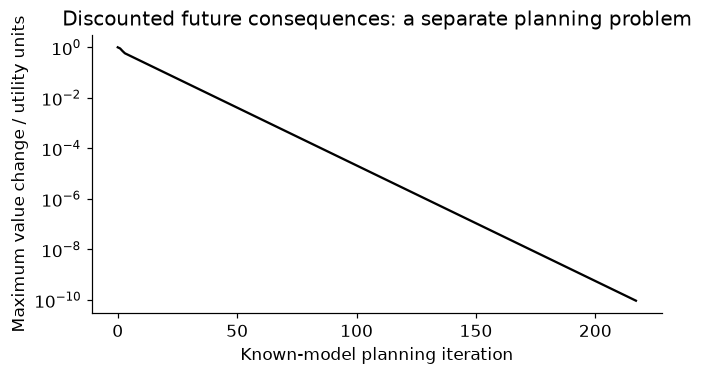

In [4]:
P=np.zeros((3,2,3));P[:,0,:]=np.array([[.85,.15,0],[0,.75,.25],[0,0,1]]);P[:,1,0]=1
reward=np.column_stack([np.array([1.,.2,-2.]),np.full(3,-.5)]);gamma=.9;value=np.zeros(3);trace=[]
assert np.allclose(P.sum(2),1) and np.all(P>=0)
for iteration in range(1000):
 q=reward+gamma*np.einsum('sak,k->sa',P,value);new=q.max(1);trace.append(float(np.max(abs(new-value))));value=new
 if trace[-1]<1e-10:break
q=reward+gamma*np.einsum('sak,k->sa',P,value);bellman=float(np.max(abs(value-q.max(1))));sequential_policy=q.argmax(1)
assert iteration<999 and bellman<1e-9 and sequential_policy.shape==(3,)
fig,ax=plt.subplots(figsize=(6,3.3));ax.semilogy(trace,'k-');ax.set(xlabel='Known-model planning iteration',ylabel='Maximum value change / utility units',title='Discounted future consequences: a separate planning problem');plt.show()
RESULTS['planning_policy']=sequential_policy.tolist();RESULTS['Bellman_residual']=bellman;RESULTS['planning_iterations']=iteration+1


<a id="taxonomy"></a>
## A four-axis worksheet for overlapping descriptions

Illustrative design: a transformer pretrained by masking historical sensor entries, later fine-tuned within a policy from logged action trajectories. This worksheet specifies a possible system. No transformer, offline-policy optimizer or deployment is implemented here. The executable model in this notebook is the tabular contextual bandit, while the sequential example is known-model planning.

Architecture describes computation; objective describes the optimized signal; adaptation describes changes in stored state or context; task describes the requested output/use. Calling the design a transformer, self-supervised, fine-tuned and a control policy can all be true. An offline-control objective needs appropriate logged action coverage and a valid evaluation design, neither supplied by a masking loss alone.


In [5]:
card={
 'architecture':'transformer over historical sensor tokens',
 'objective':'masked reconstruction pretraining; later logged-trajectory policy objective',
 'adaptation':'offline fine-tuning of declared policy/encoder parameters',
 'task':'select actions from observed history'}
assert set(card)=={'architecture','objective','adaptation','task'} and len(set(card.values()))==4
display(pd.DataFrame(card.items(),columns=['axis','illustrative design statement']))
actual={'architecture':'tabular state-action means','objective':'observed immediate reward estimation','adaptation':'online running-mean updates during training; frozen during final assessment','task':'choose one action for an independent context'}
display(pd.DataFrame(actual.items(),columns=['axis','executed bandit']))
RESULTS['taxonomy_axes']=list(card);RESULTS['transformer_worksheet_only']=True


,axis,illustrative design statement
0,architecture,transformer over historical sensor tokens
1,objective,masked reconstruction pretraining; later logge...
2,adaptation,offline fine-tuning of declared policy/encoder...
3,task,select actions from observed history


,axis,executed bandit
0,architecture,tabular state-action means
1,objective,observed immediate reward estimation
2,adaptation,online running-mean updates during training; f...
3,task,choose one action for an independent context


<a id="exercises"></a>
## Exercises and hints

1. Set exploration to zero and vary initialization on development simulations. Diagnose missing action evidence, not just a lower score.
2. Change service costs in the known Markov model and inspect which policy changes; keep planning and learned-control claims separate.
3. Give an offline logger zero probability for one action. Explain why observed rewards cannot directly assess that unseen action without added assumptions.
4. Classify the masked encoder, meta-learned initialization and contextual kernel along all four axes.
5. State what additional evidence would be required to validate the illustrative offline transformer-policy design.

**Hints:** rewards are feedback about chosen actions; other actions' rewards may be unobserved. A bandit has no action-dependent future-state transition in this example. A Bellman residual checks a declared planning problem, not empirical policy performance. See Sutton and Barto's author-hosted [Reinforcement Learning book](http://incompleteideas.net/book/the-book-2nd.html). Troubleshoot state/action IDs, visit counts, reward scale and information available at decision time before changing a policy.


In [6]:
summary={'example_id':'code_031','seed':SEED,'versions':VERSIONS,'hardware':platform.system()+' '+platform.machine()+' CPU','concepts_demonstrated':['actual contextual bandit exploration and reward fitting', 'independent frozen-policy simulation assessment', 'offline action-support diagnostic', 'known-model Bellman planning versus learning', 'four-axis taxonomy worksheet without fake transformer training'],'results':RESULTS,'elapsed_seconds':round(time.perf_counter()-START,3)}
print('EXECUTION_SUMMARY_JSON:'+json.dumps(summary,sort_keys=True,allow_nan=False))


EXECUTION_SUMMARY_JSON:{"concepts_demonstrated": ["actual contextual bandit exploration and reward fitting", "independent frozen-policy simulation assessment", "offline action-support diagnostic", "known-model Bellman planning versus learning", "four-axis taxonomy worksheet without fake transformer training"], "elapsed_seconds": 0.223, "example_id": "code_031", "hardware": "Darwin arm64 CPU", "results": {"Bellman_residual": 8.410161456140486e-11, "final_mean_reward": {"always_0": 0.08950063502811335, "always_1": 0.3522618793414959, "learned": 0.6488552676455762}, "learned_policy": [0, 1], "learned_reward_means": [[0.6984046863215989, 0.11091538448684315], [-0.5406262221498795, 0.6019262700330681]], "offline_logged_action_counts": [[98, 0], [102, 0]], "planning_iterations": 218, "planning_policy": [0, 1, 1], "taxonomy_axes": ["architecture", "objective", "adaptation", "task"], "training_action_counts": [[1901, 123], [100, 1876]], "transformer_worksheet_only": true}, "seed": 631, "versio